# Canonical K-mers and Minimisers

Select representative k-mers from overlapping windows and keep the same sequence key on either strand.

A canonical k-mer is the lexicographically smaller of a word and its reverse complement. Here each window chooses the rightmost minimum on ties. The positions are for the input orientation and repeated windows selecting the same position are collapsed.

In [1]:
from pathlib import Path
import sys

here = Path.cwd()
sys.path.insert(0, str(here.parent))
import numpy as np
import matplotlib.pyplot as plt

from genome_methods import minimisers, rc, kmers, canon, rng_dna

## Worked example

Run the example from top to bottom. The printed check and figure use the same observations.

Selected positions by window: {1: 144, 3: 73, 5: 53, 9: 27, 15: 15}


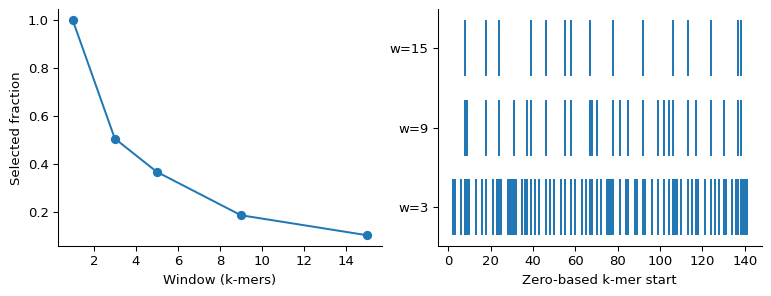

In [2]:
rng = np.random.default_rng(17)
text = rng_dna(rng, 150)
k = 7
ws = [1, 3, 5, 9, 15]
counts = [len(minimisers(text, k, w)[0]) for w in ws]
assert sorted(map(canon, kmers(text, k))) == sorted(map(canon, kmers(rc(text), k)))
print("Selected positions by window:", dict(zip(ws, counts)))
fig, (a, b) = plt.subplots(1, 2, figsize=(8, 3), constrained_layout=True)
a.plot(ws, np.array(counts) / (len(text) - k + 1), "o-")
a.set(xlabel="Window (k-mers)", ylabel="Selected fraction")
for j, w in enumerate([3, 9, 15]):
    p, _ = minimisers(text, k, w)
    b.vlines(p, j, j + 0.7)
b.set(
    xlabel="Zero-based k-mer start", yticks=[0.35, 1.35, 2.35], yticklabels=["w=3", "w=9", "w=15"]
)
plt.show()

## Interpreting the result

Wider windows usually make the sketch sparser. Local ties and repetitive sequence affect the spacing.

## Exercise

Repeat the plot on a tandem repeat and compare the rightmost tie rule with a leftmost rule.

## References

[Roberts et al., minimisers in biological sequence comparison (2004)](https://doi.org/10.1093/bioinformatics/bth408)

[Li, Minimap2 (2018)](https://doi.org/10.1093/bioinformatics/bty191)